# Assignment 4: Neural networks for EuroSAT RGB classification

Frederick Abalo

I compare CNNs trained from scratch to classify EuroSAT RGB images into 10 land use and land cover classes. The experiments test augmentation, skip connections, and dropout.

Based on the [course CNN notebook](https://colab.research.google.com/drive/1S9GDD1vCLVTzVuQsnWO1jyI5rIjx8ktK) by Xiaojiang Li.

## 1. Experiment design

| Run | Model or change | Reason |
|---|---|---|
| S | Corrected two-layer starter CNN | Establish a baseline |
| A | Deeper CNN with global average pooling | Learn more complex spatial features |
| B | A + flips and 90° rotations | Reduce dependence on image orientation |
| C | B + skip connections | Help gradients pass through the network |
| D | C + 0.25 dropout | Test whether regularization reduces overfitting |

I keep the split, seed, batch size, optimizer, schedule, and training budget fixed. A to D changes one feature at a time; S to A compares several architecture changes together. One seed gives an initial comparison, so small differences need caution.

I select the checkpoint with the highest validation accuracy, using lower validation loss to break ties. The test set is reserved for the final evaluation.


In [1]:
# Install analysis dependencies.
%pip -q install scikit-learn pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


In [5]:
import json, random, time, platform, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
EPOCHS = 30
BATCH_SIZE = 128
NUM_WORKERS = 0  # Load data in the notebook process on macOS.
PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == 'assignments':
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / 'homework4-data'
OUT = PROJECT_DIR / 'homework4-output'
OUT.mkdir(exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
environment = dict(python=platform.python_version(), torch=str(torch.__version__),
                   torchvision=str(torchvision.__version__), device=str(DEVICE),
                   gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None)
(OUT / 'environment.json').write_text(json.dumps(environment, indent=2))
print(environment)


{'python': '3.14.7', 'torch': '2.14.1', 'torchvision': '0.29.1', 'device': 'mps', 'gpu': None}


## 2. Data and preprocessing

I use a stratified 70% training, 15% validation, and 15% test split to keep class proportions similar. The proportions match the starter, but the exact images differ. The saved split manifest makes the comparison reproducible.

Normalization uses training pixels only. Flips and rotations apply only to training images; validation and test images use fixed transforms.

This is a random image split. Similar or nearby scenes may occur across partitions, so the results do not measure generalization to a new region.


In [6]:
raw = datasets.EuroSAT(root=str(DATA_DIR), download=True)
classes = raw.classes
targets = np.asarray(raw.targets)
indices = np.arange(len(raw))
train_idx, held_idx = train_test_split(indices, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(held_idx, test_size=0.50, stratify=targets[held_idx], random_state=SEED)
assert len(classes) == 10
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(raw)

manifest = pd.DataFrame([
    {'index': int(i), 'file': str(Path(raw.samples[i][0]).relative_to(DATA_DIR)),
     'label': classes[targets[i]], 'split': split}
    for split, ids in [('train', train_idx), ('validation', val_idx), ('test', test_idx)] for i in ids
])
manifest.to_csv(OUT / 'split_manifest.csv', index=False)
display(pd.crosstab(manifest['label'], manifest['split']))
print('Image dimensions:', raw[0][0].size)


split,test,train,validation
label,,,
AnnualCrop,450,2100,450
Forest,450,2100,450
HerbaceousVegetation,450,2100,450
Highway,375,1750,375
Industrial,375,1750,375
Pasture,300,1400,300
PermanentCrop,375,1750,375
Residential,450,2100,450
River,375,1750,375


Image dimensions: (64, 64)


Training mean: [0.3438941538333893, 0.3799557387828827, 0.4075563848018646] Training std: [0.2034444510936737, 0.13642366230487823, 0.11470609158277512]


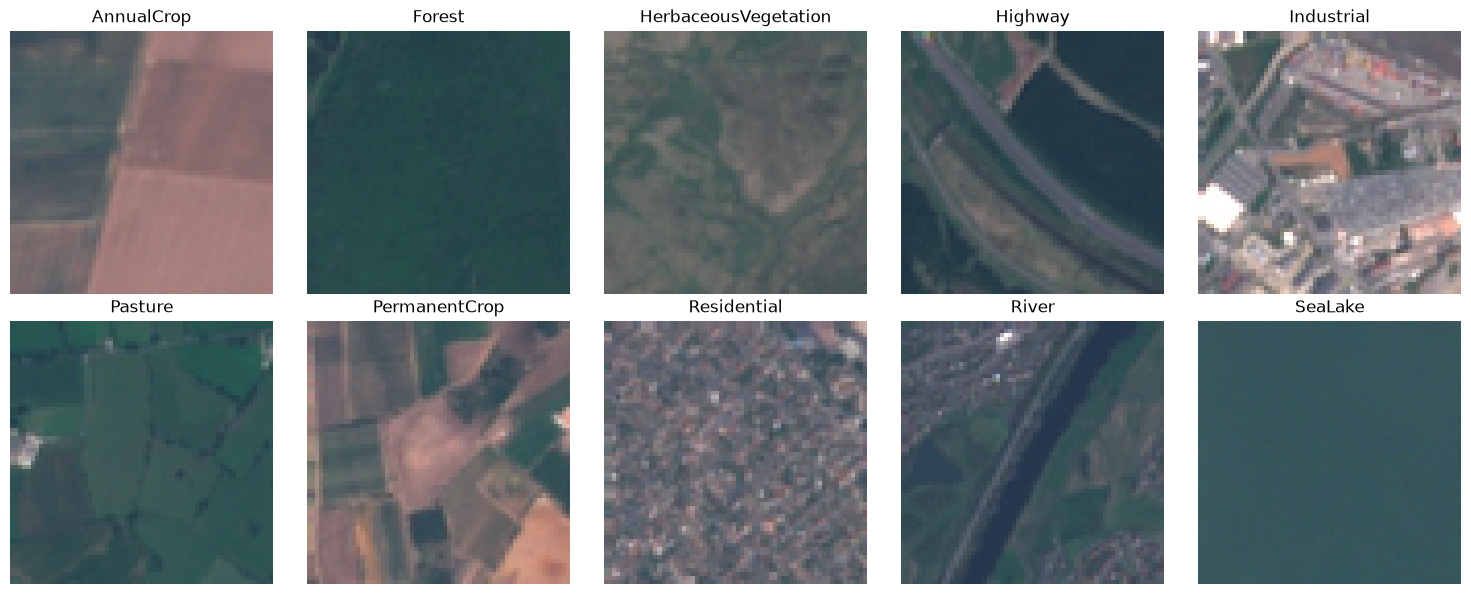

In [7]:
class ImageSubset(Dataset):
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, list(indices), transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        image, label = self.base[int(self.indices[idx])]
        return self.transform(image), label

# Estimate channel statistics from unaugmented training pixels.
stats_loader = DataLoader(ImageSubset(raw, train_idx, transforms.ToTensor()),
                          batch_size=256, num_workers=NUM_WORKERS)
channel_sum = torch.zeros(3, dtype=torch.float64)
channel_sq = torch.zeros(3, dtype=torch.float64)
pixels = 0
for images, _ in stats_loader:
    images = images.double()
    channel_sum += images.sum((0, 2, 3))
    channel_sq += images.square().sum((0, 2, 3))
    pixels += images.shape[0] * images.shape[2] * images.shape[3]
mean = (channel_sum / pixels).float()
std = (channel_sq / pixels - mean.double().square()).clamp_min(1e-12).sqrt().float()
(OUT / 'normalization.json').write_text(json.dumps({'mean': mean.tolist(), 'std': std.tolist()}, indent=2))
print('Training mean:', mean.tolist(), 'Training std:', std.tolist())

class RandomQuarterTurn:
    def __call__(self, image):
        return TF.rotate(image, 90 * random.randrange(4))

def image_transform(augment=False):
    ops = [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), RandomQuarterTurn()] if augment else []
    return transforms.Compose(ops + [transforms.ToTensor(), transforms.Normalize(mean.tolist(), std.tolist())])

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(ids, augment=False, shuffle=False, seed=SEED):
    return DataLoader(ImageSubset(raw, ids, image_transform(augment)),
                      batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == 'cuda', worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(seed))

val_loader = make_loader(val_idx)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for label, ax in enumerate(axes.flat):
    i = next(int(i) for i in train_idx if targets[i] == label)
    ax.imshow(raw[i][0]); ax.set_title(classes[label]); ax.axis('off')
plt.tight_layout(); plt.show()


## 3. Model design

I keep the images at their native 64 × 64 resolution and use training statistics for normalization. The starter baseline has two convolution layers and a dense classifier. Its dense layer is defined in `__init__` so the optimizer includes all parameters. In the original starter, replacing this layer during the first forward pass leaves its new parameters outside the optimizer.

The custom CNN has four blocks with 32, 64, 128, and 256 channels. Three downsampling steps reduce the feature maps to 8 × 8. Batch normalization and ReLU follow the convolutions. Global average pooling limits classifier parameters, and the final layer produces 10 logits for cross entropy.

Skip connections add each block's input to its output. A 1 × 1 projection matches dimensions where needed. Both versions contain the same projections, but only the residual version adds them to the main path. This keeps total parameter counts equal, although unused projections receive no gradient in the plain model.

The deeper layers can combine local textures into larger patterns. Skip connections may improve optimization, while dropout may reduce overfitting. The experiments test whether these choices help.

All models use the same preprocessing and AdamW settings. The starter baseline therefore measures its architecture under this training setup, rather than reproducing its original 224 × 224 SGD run.


In [8]:
class StarterCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 14 * 14, 128),
                                        nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

class ConvBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, residual=True):
        super().__init__()
        self.residual = residual
        self.main = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = (nn.Identity() if cin == cout and stride == 1 else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout)))
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        features = self.main(x)
        skip = self.skip(x)
        return self.relu(features + skip if self.residual else features)

class LandCoverCNN(nn.Module):
    def __init__(self, residual=False, dropout=0.0):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.blocks = nn.Sequential(ConvBlock(32, 32, residual=residual),
            ConvBlock(32, 64, 2, residual), ConvBlock(64, 128, 2, residual),
            ConvBlock(128, 256, 2, residual))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(dropout), nn.Linear(256, 10))
    def forward(self, x):
        return self.head(self.blocks(self.stem(x)))

for residual in [False, True]:
    model = LandCoverCNN(residual=residual)
    assert model(torch.zeros(2, 3, 64, 64)).shape == (2, 10)
    print('Residual:', residual, 'parameters:', sum(p.numel() for p in model.parameters()))
del model

def build_model(config):
    if config['name'] == 'S_corrected_starter':
        return StarterCNN()
    return LandCoverCNN(config['residual'], config['dropout'])


Residual: False parameters: 1228970
Residual: True parameters: 1228970


## 4. Training

I use AdamW with a learning rate of 0.001, weight decay of 0.0001, and a cosine schedule over 30 epochs. Each experiment starts from fresh weights. Saving parameter copies preserves the best validation checkpoint as training continues.

Training accuracy includes augmentation and dropout where enabled. Validation uses the model at the end of each epoch with both disabled, so the gap reflects these differences as well as generalization.


In [9]:
def pass_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n

EXPERIMENTS = [
    dict(name='S_corrected_starter', residual=False, augment=False, dropout=0.0),
    dict(name='A_plain', residual=False, augment=False, dropout=0.0),
    dict(name='B_plain_aug', residual=False, augment=True, dropout=0.0),
    dict(name='C_residual_aug', residual=True, augment=True, dropout=0.0),
    dict(name='D_residual_aug_dropout', residual=True, augment=True, dropout=0.25),
]

def train_experiment(config, seed=SEED):
    seed_everything(seed)
    loader = make_loader(train_idx, augment=config['augment'], shuffle=True, seed=seed)
    model = build_model(config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    criterion = nn.CrossEntropyLoss()
    best_key, best_epoch, history = (-1.0, -float('inf')), 0, []
    path = OUT / f"{config['name']}_seed{seed}.pt"
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        lr = optimizer.param_groups[0]['lr']
        train_loss, train_acc = pass_epoch(model, loader, criterion, optimizer)
        val_loss, val_acc = pass_epoch(model, val_loader, criterion)
        scheduler.step()
        history.append(dict(epoch=epoch, lr=lr, train_loss=train_loss, train_acc=train_acc,
                            val_loss=val_loss, val_acc=val_acc))
        if (val_acc, -val_loss) > best_key:
            best_key, best_epoch = (val_acc, -val_loss), epoch
            torch.save(dict(state_dict={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                config=config, seed=seed, epoch=epoch, val_accuracy=val_acc, val_loss=val_loss,
                classes=classes, mean=mean.tolist(), std=std.tolist(), epochs=EPOCHS), path)
        pd.DataFrame(history).to_csv(OUT / f"{config['name']}_seed{seed}_history.csv", index=False)
        print(f"{config['name']} | {epoch:02d}/{EPOCHS} | train {train_acc:.3f} | val {val_acc:.3f} | val loss {val_loss:.3f}")
    result = dict(**config, seed=seed, best_epoch=best_epoch, val_accuracy=best_key[0],
                  val_loss=-best_key[1], parameters=sum(p.numel() for p in model.parameters()),
                  minutes=(time.perf_counter() - started) / 60, checkpoint=str(path))
    del model, optimizer
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result


In [10]:
# Rerunning replaces the previous experiment files.
results = []
for config in EXPERIMENTS:
    results.append(train_experiment(config))
    pd.DataFrame(results).to_csv(OUT / 'experiments.csv', index=False)
comparison = pd.DataFrame(results).sort_values(['val_accuracy', 'val_loss'], ascending=[False, True])
display(comparison.drop(columns='checkpoint'))


S_corrected_starter | 01/30 | train 0.658 | val 0.712 | val loss 0.816
S_corrected_starter | 02/30 | train 0.798 | val 0.803 | val loss 0.546
S_corrected_starter | 03/30 | train 0.840 | val 0.809 | val loss 0.573
S_corrected_starter | 04/30 | train 0.868 | val 0.821 | val loss 0.502
S_corrected_starter | 05/30 | train 0.889 | val 0.837 | val loss 0.489
S_corrected_starter | 06/30 | train 0.911 | val 0.844 | val loss 0.466
S_corrected_starter | 07/30 | train 0.933 | val 0.855 | val loss 0.485
S_corrected_starter | 08/30 | train 0.944 | val 0.847 | val loss 0.510
S_corrected_starter | 09/30 | train 0.961 | val 0.825 | val loss 0.598
S_corrected_starter | 10/30 | train 0.967 | val 0.824 | val loss 0.607
S_corrected_starter | 11/30 | train 0.975 | val 0.848 | val loss 0.564
S_corrected_starter | 12/30 | train 0.980 | val 0.860 | val loss 0.525
S_corrected_starter | 13/30 | train 0.985 | val 0.843 | val loss 0.660
S_corrected_starter | 14/30 | train 0.988 | val 0.843 | val loss 0.636
S_corr

,name,residual,augment,dropout,seed,best_epoch,val_accuracy,val_loss,parameters,minutes
2,B_plain_aug,False,True,0.00,42,27,0.976790,0.071030,1228970,6.538796
3,C_residual_aug,True,True,0.00,42,30,0.974568,0.079111,1228970,7.024274
4,D_residual_aug_dropout,True,True,0.25,42,28,0.972593,0.075676,1228970,6.771083
1,A_plain,False,False,0.00,42,25,0.972593,0.101129,1228970,6.514345
0,S_corrected_starter,False,False,0.00,42,29,0.866420,0.695518,1626442,2.564416


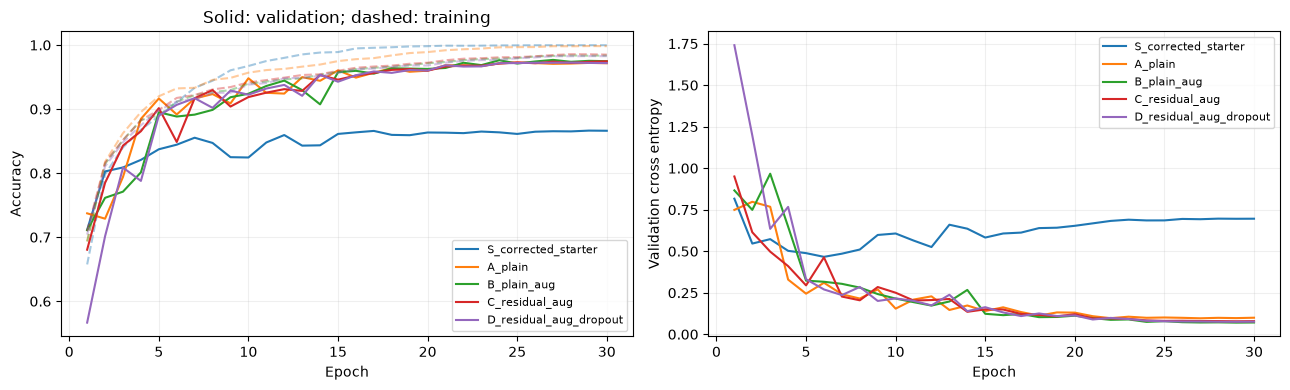

,validation_accuracy,change_from_previous_percentage_points
name,,
S_corrected_starter,0.866420,NaN
A_plain,0.972593,10.617284
B_plain_aug,0.976790,0.419753
C_residual_aug,0.974568,-0.222222
D_residual_aug_dropout,0.972593,-0.197531


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for result in results:
    h = pd.read_csv(OUT / f"{result['name']}_seed{result['seed']}_history.csv")
    line, = axes[0].plot(h.epoch, h.val_acc, label=result['name'])
    axes[0].plot(h.epoch, h.train_acc, '--', alpha=.4, color=line.get_color())
    axes[1].plot(h.epoch, h.val_loss, label=result['name'])
axes[0].set(xlabel='Epoch', ylabel='Accuracy', title='Solid: validation; dashed: training')
axes[1].set(xlabel='Epoch', ylabel='Validation cross entropy')
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(OUT / 'learning_curves.png', dpi=160); plt.show()

ordered = pd.DataFrame(results).set_index('name').loc[[c['name'] for c in EXPERIMENTS]]
deltas = 100 * ordered.val_accuracy.diff()
display(pd.DataFrame({'validation_accuracy': ordered.val_accuracy,
                      'change_from_previous_percentage_points': deltas}))


## 5. Test evaluation

The selected validation checkpoint is evaluated on the held-out test set. Accuracy measures overall correctness, while macro F1 gives each class equal weight. The confusion matrix and example errors show which classes are harder to distinguish.

Model choices are fixed before examining test results to avoid tuning to the test set.


model                  B_plain_aug
best_epoch                      27
validation_accuracy        0.97679
test_accuracy             0.977284
test_macro_f1             0.976674
n_test                        4050
dtype: object

,precision,recall,f1-score,support
AnnualCrop,0.943723,0.968889,0.956140,450.000000
Forest,0.993363,0.997778,0.995565,450.000000
HerbaceousVegetation,0.973392,0.975556,0.974473,450.000000
Highway,0.968586,0.986667,0.977543,375.000000
Industrial,0.989305,0.986667,0.987984,375.000000
Pasture,0.976510,0.970000,0.973244,300.000000
PermanentCrop,0.974930,0.933333,0.953678,375.000000
Residential,0.995546,0.993333,0.994438,450.000000
River,0.965147,0.960000,0.962567,375.000000
SeaLake,0.991111,0.991111,0.991111,450.000000


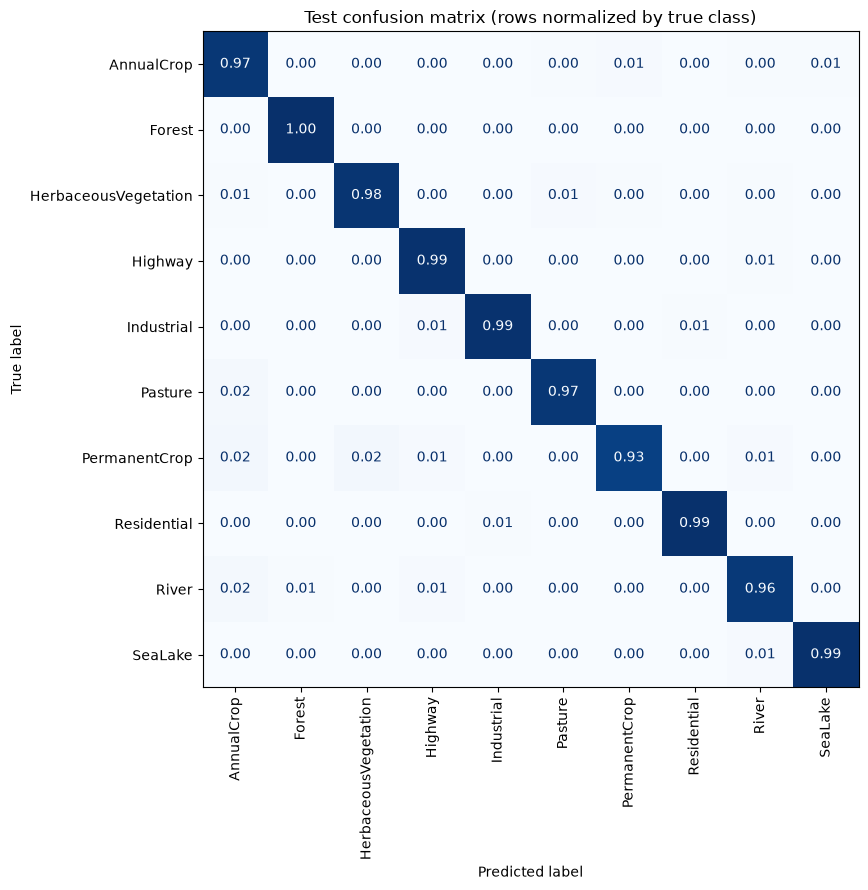

In [12]:
winner = comparison.iloc[0]
checkpoint = torch.load(winner.checkpoint, map_location='cpu', weights_only=True)
selected = build_model(checkpoint['config']).to(DEVICE)
selected.load_state_dict(checkpoint['state_dict'])
selected.eval()
test_loader = make_loader(test_idx)
truth, predictions, confidence = [], [], []
with torch.inference_mode():
    for x, y in test_loader:
        probs = selected(x.to(DEVICE)).softmax(1).cpu()
        truth.extend(y.tolist())
        predictions.extend(probs.argmax(1).tolist())
        confidence.extend(probs.max(1).values.tolist())
truth, predictions = np.asarray(truth), np.asarray(predictions)
test_metrics = dict(model=str(winner['name']), best_epoch=int(winner.best_epoch),
                    validation_accuracy=float(winner.val_accuracy),
                    test_accuracy=accuracy_score(truth, predictions),
                    test_macro_f1=f1_score(truth, predictions, average='macro'), n_test=len(truth))
(OUT / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))
display(pd.Series(test_metrics))
report = classification_report(truth, predictions, labels=list(range(10)), target_names=classes,
                               output_dict=True, zero_division=0)
display(pd.DataFrame(report).T)
pd.DataFrame(report).T.to_csv(OUT / 'classification_report.csv')
pd.DataFrame({'index': test_idx,
    'file': [str(Path(raw.samples[int(i)][0]).relative_to(DATA_DIR)) for i in test_idx],
    'true': [classes[i] for i in truth], 'predicted': [classes[i] for i in predictions],
    'confidence': confidence}).to_csv(OUT / 'test_predictions.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(truth, predictions, labels=list(range(10)), display_labels=classes,
                                       normalize='true', values_format='.2f', cmap='Blues', ax=ax,
                                       xticks_rotation=90, colorbar=False)
ax.set_title('Test confusion matrix (rows normalized by true class)')
plt.tight_layout(); plt.savefig(OUT / 'confusion_matrix.png', dpi=160); plt.show()


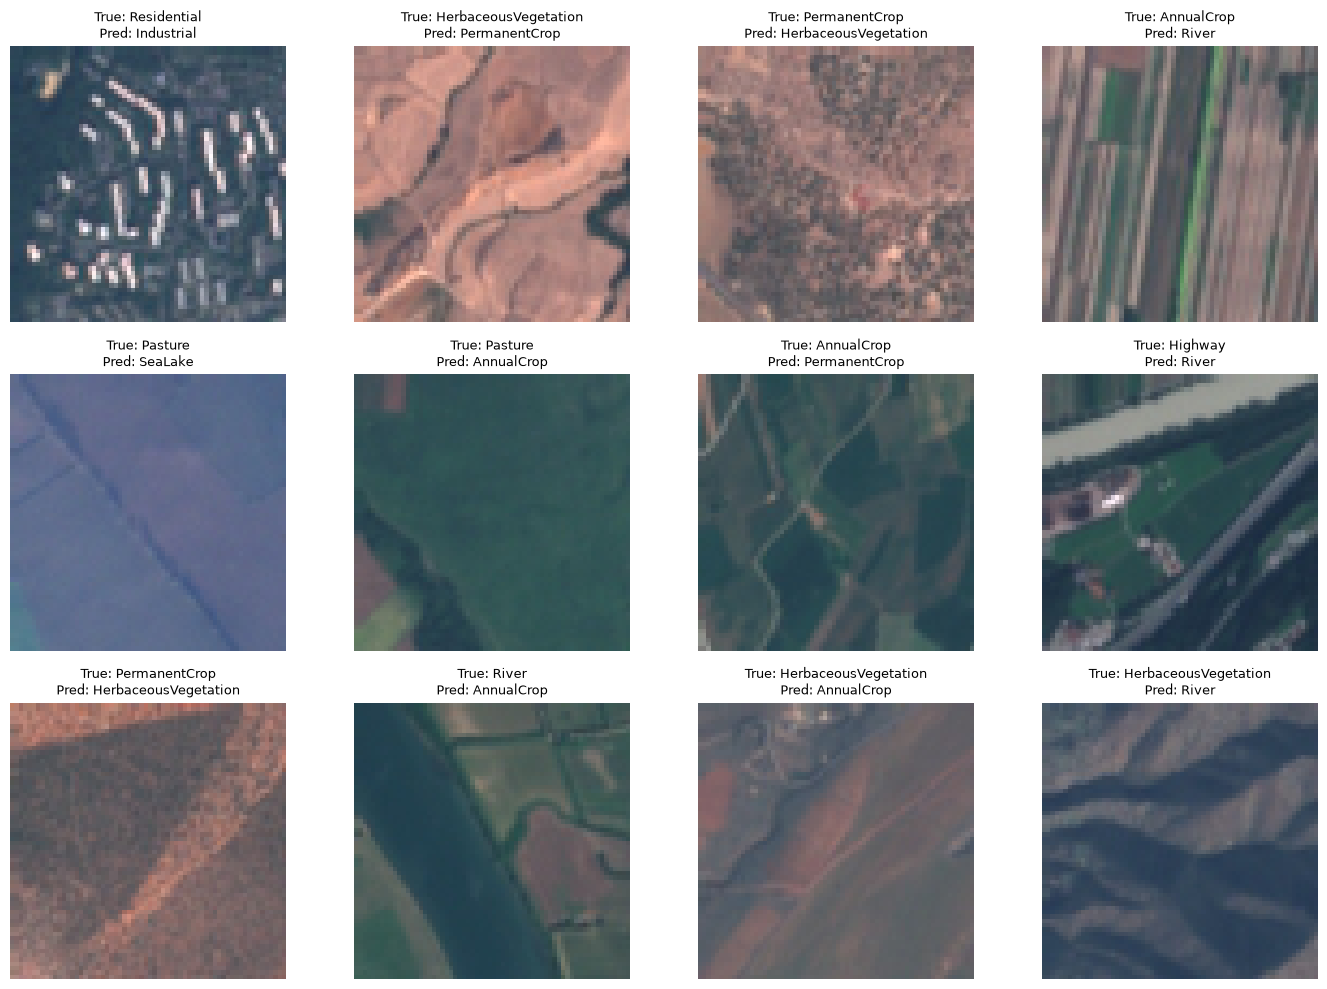

In [13]:
wrong = np.flatnonzero(truth != predictions)
if len(wrong):
    # Use a fixed random sample of misclassified images.
    show = np.random.default_rng(SEED).choice(wrong, size=min(12, len(wrong)), replace=False)
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    for ax in axes.flat:
        ax.axis('off')
    for ax, j in zip(axes.flat, show):
        ax.imshow(raw[int(test_idx[j])][0])
        ax.set_title(f'True: {classes[truth[j]]}\nPred: {classes[predictions[j]]}', fontsize=9)
    plt.tight_layout(); plt.savefig(OUT / 'example_errors.png', dpi=160); plt.show()
else:
    print('No test errors in this run.')


## 6. Results and discussion

| Model | Best epoch | Validation accuracy | Validation loss |
|---|---:|---:|---:|
| S: starter | 29 | 86.64% | 0.6955 |
| A: deeper CNN | 25 | 97.26% | 0.1011 |
| B: CNN + augmentation | 27 | 97.68% | 0.0710 |
| C: residual + augmentation | 30 | 97.46% | 0.0791 |
| D: residual + augmentation + dropout | 28 | 97.26% | 0.0757 |

I selected the plain CNN with flips and rotations (B) at epoch 27 because it had the highest validation accuracy, 97.68%. On the 4,050 held-out test images, it correctly classified 3,958 images and made 92 errors. Test accuracy was 97.73%, and macro F1 was 0.9767. Validation and test accuracy differed by 0.05 percentage points.

### What helped

The deeper CNN improved validation accuracy by 10.62 percentage points over the corrected starter. It also used fewer parameters: 1,228,970 compared with 1,626,442. The starter reached almost 100% training accuracy but only 86.64% validation accuracy, and its validation loss rose later in training. This indicates overfitting. The deeper model combines convolutional features with global average pooling instead of a large flattened classifier. These changes improved generalization together; this comparison does not isolate their individual effects.

Adding flips and rotations improved validation accuracy by another 0.42 percentage points and lowered validation loss from 0.1011 to 0.0710. At its selected epoch, B had 98.30% training accuracy and 97.68% validation accuracy. The smaller gap is consistent with augmentation reducing reliance on the training images' orientations, although training accuracy includes random transforms.

### What did not help

Skip connections reduced best validation accuracy by 0.22 percentage points relative to B. Adding dropout to the residual model reduced it by a further 0.20 points. Neither change improved validation accuracy in this run. The differences are small and come from one seed, so they do not show that residual connections or dropout are generally ineffective. I kept B because the extra changes did not improve the selection metric.

### Remaining errors

PermanentCrop had the lowest recall, 93.33%, with 25 of 375 images misclassified. Nine were predicted as AnnualCrop and nine as HerbaceousVegetation. AnnualCrop and PermanentCrop had the lowest class F1 scores, 0.9561 and 0.9537. The example errors show similar field textures and vegetation colors, which may make these classes difficult to separate in RGB images. Forest had the highest F1, 0.9956.

### Limits

These results come from one stratified random split and one training seed. Similar or nearby scenes may occur in different partitions, so the score does not establish performance in a new geographic region. All models shared the same optimizer settings and 30-epoch budget; the search did not cover other learning rates, widths, or longer schedules. Repeating the leading configurations across seeds and using a geographic holdout would strengthen the evidence. The final model was selected using validation results, with the test set used afterward for evaluation.


In [14]:
# Archive checkpoints, metrics, and figures.
archive = shutil.make_archive(str(PROJECT_DIR / 'homework4-results'), 'zip', root_dir=OUT)
print('Saved:', archive)
try:
    from google.colab import files
except ImportError:
    print('Local run: outputs are in', OUT.resolve())
else:
    files.download(archive)


Saved: /Users/freddie/Projects/HailMary/ai-urban-sustainability/homework4-results.zip
Local run: outputs are in /Users/freddie/Projects/HailMary/ai-urban-sustainability/homework4-output


## Sources

- [Course CNN notebook](https://colab.research.google.com/drive/1S9GDD1vCLVTzVuQsnWO1jyI5rIjx8ktK)
- [EuroSAT dataset and paper](https://github.com/phelber/EuroSAT)
- [torchvision EuroSAT loader](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.EuroSAT.html)
- [PyTorch checkpoint saving and loading](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)
